# Thermal diffusive waves in a Cu rod — 10 mHz
**Experiment 2.3: Temperature oscillations in a metal (PhysLogger)** · Analysis notebook for the **10 mHz** data set.

Every manual question from Q8 onward that needs Python is answered below, in order. Cells are numbered by question.
Change only the *Setup* cell to re-use this notebook for another data set.

In [1]:
import numpy as np, pandas as pd, json, matplotlib.pyplot as plt
from scipy import stats, signal
plt.rcParams.update({"figure.dpi":110,"axes.grid":True,"font.size":10})

# ---------------- Setup ----------------
LABEL    = "10mHz"
CSV      = r"/mnt/user-data/uploads/Time-T_A___ºC__T_B_T_C_T_D_PhysWatt_VoltageA_1--10mHz.csv"
F_NOM    = 10e-3          # nominal heater frequency set on PhysLogger [Hz]
DX       = 0.03                    # spacing between thermocouples [m] (manual: 3 cm; AJP paper: 3.3 cm)
# Position order from heater, decided from DATA (largest oscillation amplitude = nearest the heater):
ORDER    = ["TC","TD","TB","TA"]   # x = 0, DX, 2DX, 3DX
D_REF    = 1.02e-4                 # accepted diffusivity of Cu [m^2/s] (AJP 2014 paper)
RHO, CP  = 8960.0, 385.0           # Cu density [kg/m^3], specific heat [J/kg/K]
P_RATED, V_RATED = 40.0, 12.0      # heater rating [W], [V]
ROD_DIAM = 0.030                   # [m]
x = DX*np.arange(len(ORDER))

import sys; sys.path.insert(0, ".")
from thermal_utils import load
df = load(CSV)
print(len(df), "samples, dt = %.3f s, duration = %.0f s" % (np.median(np.diff(df.t)), df.t.iloc[-1]))
df.head()

19004 samples, dt = 0.508 s, duration = 9633 s


,n,t,TA,TB,TC,TD,V
0,1,0.0000,207.991,100.073,20.400,19.615,0.006634
1,2,0.5082,208.927,99.988,19.550,19.319,0.006720
2,3,1.0200,206.942,102.052,20.720,19.403,0.006562
3,4,1.5270,207.350,101.460,20.030,19.965,0.006640
4,5,2.0340,208.814,95.641,20.567,19.622,0.006598


## Q8 — Fourier transform of a simulated square pulse
Only odd harmonics appear (with amplitudes ∝ 1/n), exactly as in Eq. (11) of the manual.

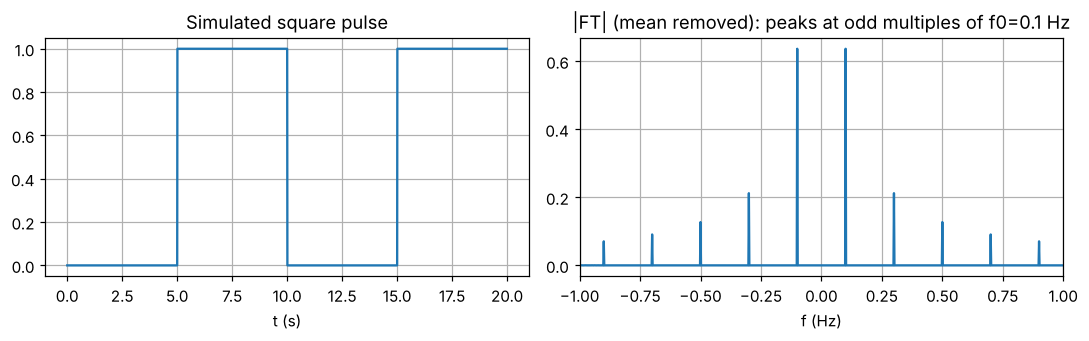

n=1: |c|=0.6366   theory (2/(n pi) odd, 0 even)=0.6366
n=2: |c|=0.0000   theory (2/(n pi) odd, 0 even)=0.0000
n=3: |c|=0.2122   theory (2/(n pi) odd, 0 even)=0.2122
n=4: |c|=0.0000   theory (2/(n pi) odd, 0 even)=0.0000
n=5: |c|=0.1273   theory (2/(n pi) odd, 0 even)=0.1273


In [2]:
fs=100; T0=10; tt=np.arange(0,50*T0,1/fs); sq=(np.sin(2*np.pi*tt/T0)<0).astype(float)  # 0/1 square, A=1
S=np.fft.fftshift(np.fft.fft(sq-sq.mean()))/len(sq)*2; ff=np.fft.fftshift(np.fft.fftfreq(len(sq),1/fs))
fig,ax=plt.subplots(1,2,figsize=(10,3.2))
ax[0].plot(tt[:2000],sq[:2000]); ax[0].set_title("Simulated square pulse"); ax[0].set_xlabel("t (s)")
ax[1].plot(ff,abs(S)); ax[1].set_xlim(-1,1); ax[1].set_title("|FT| (mean removed): peaks at odd multiples of f0=0.1 Hz"); ax[1].set_xlabel("f (Hz)")
plt.tight_layout(); plt.show()
for n in (1,2,3,4,5): i=np.argmin(abs(ff-n/T0)); print(f"n={n}: |c|={abs(S[i]):.4f}   theory (2/(n pi) odd, 0 even)={2/(n*np.pi) if n%2 else 0:.4f}")

## Q13 — Depth reached by the daily temperature cycle (numerical check)
δ = √(2D/Ω) with D ≈ 1 mm²/s and Ω = 2π/(24 h).

In [3]:
Om=2*np.pi/(24*3600); Dg=1e-6
print("skin depth δ = %.3f m ;  amplitude down to 1%% at ≈ %.2f m (4.6 δ)" % (np.sqrt(2*Dg/Om), 4.6*np.sqrt(2*Dg/Om)))

skin depth δ = 0.166 m ;  amplitude down to 1% at ≈ 0.76 m (4.6 δ)


## Data cleaning
PhysLogger thermocouples occasionally give single-sample spikes (e.g. −697 °C). A Hampel filter (11-point rolling median, 5×MAD) replaces only those outliers.

In [4]:
def hampel(y, w=11, k=5.0):
    s=pd.Series(y); med=s.rolling(w,center=True,min_periods=1).median()
    mad=(s-med).abs().rolling(w,center=True,min_periods=1).median()*1.4826
    bad=(s-med).abs()>np.maximum(k*mad,1.0)
    out=s.copy(); out[bad]=med[bad]; return out.values, bad.values
t=df.t.values; T={}
for ch in ["TA","TB","TC","TD"]:
    T[ch],bad=hampel(df[ch].values); print(ch,"outliers replaced:",bad.sum())
V=df.V.values

TA outliers replaced: 79
TB outliers replaced: 52
TC outliers replaced: 78
TD outliers replaced: 68


## Heater period and frequency
Rising edges of the PhysWatt voltage (linear-interpolated threshold crossings) give the true heater frequency. Irregular start-up cycles are rejected.

In [5]:
thr=0.5*V.max(); hi=V>thr; idx=np.where(~hi[:-1]&hi[1:])[0]
te=t[idx]+(thr-V[idx])/(V[idx+1]-V[idx])*(t[idx+1]-t[idx])
P0=1/F_NOM; ok=np.abs(np.diff(te)-np.median(np.diff(te)))<0.05*np.median(np.diff(te))
good=np.r_[ok,False]|np.r_[False,ok]; te_g=te[good]
k=np.round((te_g-te_g[0])/np.median(np.diff(te))).astype(int)
fit=stats.linregress(k,te_g); P=fit.slope; f0=1/P
print(f"Heater period P = {P:.3f} s  ->  f0 = {f0*1e3:.4f} mHz   (set: {F_NOM*1e3} mHz),  omega0 = {2*np.pi*f0:.5f} rad/s")
duty=hi[t>t[idx[0]]].mean(); Vhi=V[hi].mean(); print(f"duty cycle = {duty:.3f}, heater high level = {Vhi:.2f} V")
w0=2*np.pi*f0

Heater period P = 100.000 s  ->  f0 = 10.0000 mHz   (set: 10.0 mHz),  omega0 = 0.06283 rad/s
duty cycle = 0.501, heater high level = 11.70 V


## Q15 — All thermocouple data

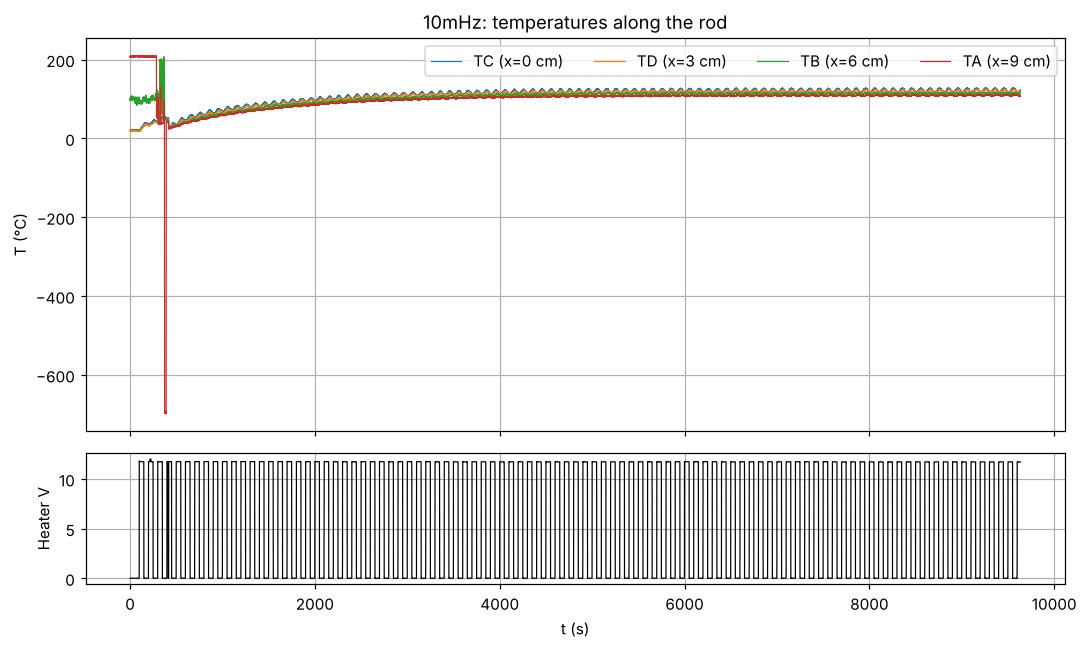

In [6]:
fig,ax=plt.subplots(2,1,figsize=(10,6),sharex=True,gridspec_kw={"height_ratios":[3,1]})
for ch in ORDER: ax[0].plot(t,T[ch],lw=.8,label=f"{ch} (x={x[ORDER.index(ch)]*100:.0f} cm)")
ax[0].set_ylabel("T (°C)"); ax[0].legend(ncol=4); ax[0].set_title(f"{LABEL}: temperatures along the rod")
ax[1].plot(t,V,"k",lw=.8); ax[1].set_ylabel("Heater V"); ax[1].set_xlabel("t (s)"); plt.tight_layout(); plt.show()

**Observation (fill in your words):** each thermocouple oscillates at the heater frequency on top of a slowly rising mean; amplitude shrinks and the signal lags more with distance from the heater. The thermocouple *nearest* the heater has the largest swing. From the data, the ordering by amplitude/phase is **TC → TD → TB → TA** (TC nearest the heater), *not* A→D — channels were not plugged in in distance order. This is checked quantitatively below.

## Q14 — How to confirm dynamic equilibrium?
The cycle-averaged temperature stops drifting. We compute the mean over each heater period and wait until it is within 3 % of the total rise from its final value, for all channels.

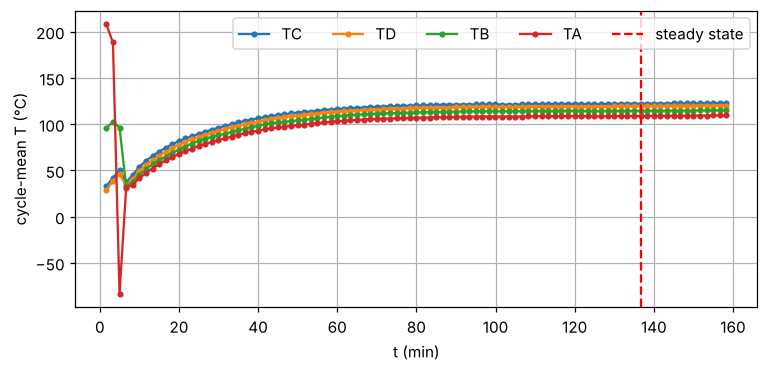

Dynamic equilibrium from cycle 81, t_ss = 8199 s (136.7 min); steady-state cycles used: 13


In [7]:
edges=te_g[0]+P*np.arange(0,int((t[-1]-te_g[0])//P))
cm={ch:np.array([T[ch][(t>=a)&(t<a+P)].mean() for a in edges]) for ch in ORDER}
ss=[]
for ch in ORDER:
    rise=cm[ch][-1]-cm[ch][0]; far=np.abs(cm[ch]-cm[ch][-1])>0.03*abs(rise)
    ss.append(np.where(far)[0].max()+1 if far.any() else 0)
k_ss=min(max(ss),len(edges)-6); t_ss=edges[k_ss]
plt.figure(figsize=(8,3.5))
for ch in ORDER: plt.plot(edges/60,cm[ch],"o-",ms=3,label=ch)
plt.axvline(t_ss/60,color="r",ls="--",label="steady state"); plt.xlabel("t (min)"); plt.ylabel("cycle-mean T (°C)"); plt.legend(ncol=5); plt.show()
print(f"Dynamic equilibrium from cycle {k_ss}, t_ss = {t_ss:.0f} s ({t_ss/60:.1f} min); steady-state cycles used: {len(edges)-1-k_ss}")
m=(t>=edges[k_ss])&(t<edges[-1]+P*0)  # integer number of cycles
tw=t[m]; N=len(tw); ncyc=len(edges)-1-k_ss
Y={}
for ch in ORDER:   # remove the slow residual drift (linear trend) so it cannot leak into the harmonics
    yy=T[ch][m]; p=np.polyfit(tw-tw.mean(),yy,1); Y[ch]=yy-p[0]*(tw-tw.mean())

## Q16 — Fourier transform; the zero-frequency peak
The FT is `fftshift(fft(y))`. The peak at **f = 0** is the **mean (DC) temperature** of the signal — it is large because the rod sits well above room temperature — and is removed by subtracting the mean before the FFT. Horizontal axis: frequency in Hz (f = k·fs/N).

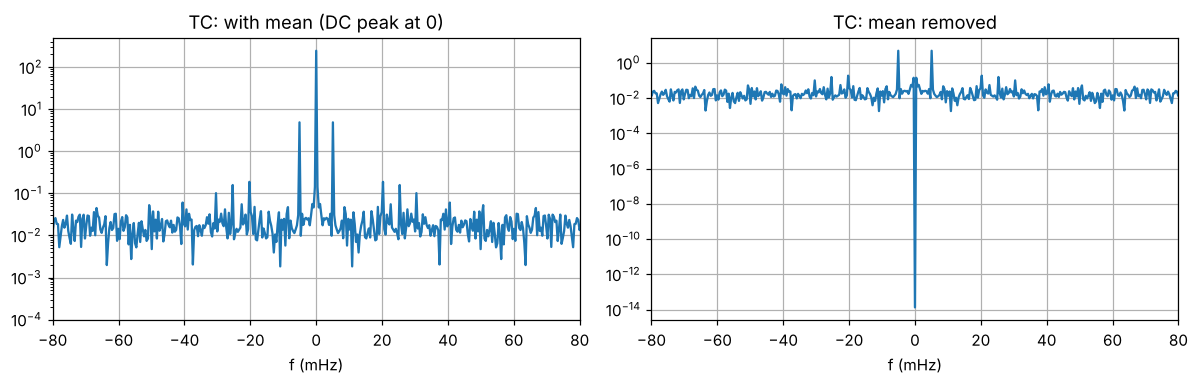

In [8]:
fs=1/np.median(np.diff(tw)); fr=np.fft.fftshift(np.fft.fftfreq(N,1/fs))
fig,ax=plt.subplots(1,2,figsize=(11,3.6))
y=Y["TC"]; 
for a,yy,ttl in ((ax[0],y,"with mean (DC peak at 0)"),(ax[1],y-y.mean(),"mean removed")):
    a.plot(fr*1e3,abs(np.fft.fftshift(np.fft.fft(yy)))/N*2); a.set_xlim(-8*f0*1e3,8*f0*1e3); a.set_yscale("log"); a.set_xlabel("f (mHz)"); a.set_title("TC: "+ttl)
plt.tight_layout(); plt.show()

## Harmonic amplitudes and phases (DFT at the exact harmonic frequencies)
The window contains an integer number of heater cycles, so harmonics are orthogonal. For each channel and odd harmonic *n*: amplitude A and phase lag. Only the lowest three odd harmonics (n = 1, 3, 5, as in the AJP paper) are analysed, and a harmonic is kept only if it exceeds 5× the high-frequency noise floor at **at least 3** sensors.

In [9]:
def dft(y,tw,f):
    c=np.sum((y-y.mean())*np.exp(-2j*np.pi*f*tw))*2/len(tw); return c
Nyq=fs/2; freqs=np.fft.rfftfreq(N,1/fs)
noise={}
for ch in ORDER:
    A=abs(np.fft.rfft(Y[ch]-Y[ch].mean()))*2/N; noise[ch]=np.median(A[(freqs>12*f0)&(freqs<Nyq)])
rows=[]
for n in (1,3,5):
    for ch in ORDER:
        c=dft(Y[ch],tw,n*f0); rows.append(dict(n=n,ch=ch,x=x[ORDER.index(ch)],A=abs(c),arg=np.angle(c),snr=abs(c)/noise[ch]))
H=pd.DataFrame(rows); good_n=[n for n in (1,3,5) if (H[H.n==n].snr>5).sum()>=3]
print("noise floor (°C):",{k:round(v,4) for k,v in noise.items()}); print("usable harmonics:",good_n)
H.pivot(index="n",columns="ch",values="A")[ORDER].round(3)

noise floor (°C): {'TC': np.float64(0.0168), 'TD': np.float64(0.0171), 'TB': np.float64(0.0147), 'TA': np.float64(0.0165)}
usable harmonics: [1]


ch,TC,TD,TB,TA
n,,,,
1,4.868,3.531,1.228,1.278
3,0.004,0.498,0.074,0.078
5,0.163,0.105,0.016,0.018


## Q22 — Fourier transform of your data (all four thermocouples)
Odd harmonics of the heater frequency are visible; closer-to-heater sensors have the bigger peaks; higher harmonics fade.

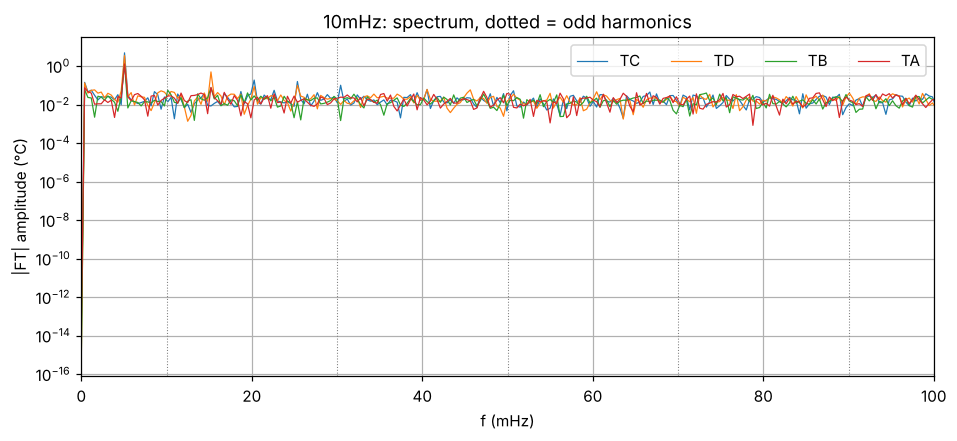

In [10]:
plt.figure(figsize=(10,4))
for ch in ORDER:
    A=abs(np.fft.rfft(Y[ch]-Y[ch].mean()))*2/N; plt.semilogy(freqs*1e3,A,lw=.8,label=ch)
for n in range(1,10,2): plt.axvline(n*f0*1e3,color="gray",ls=":",lw=.7)
plt.xlim(0,10*f0*1e3); plt.xlabel("f (mHz)"); plt.ylabel("|FT| amplitude (°C)"); plt.title(f"{LABEL}: spectrum, dotted = odd harmonics"); plt.legend(ncol=4); plt.show()

## Q17 — Damping length of each harmonic
For harmonic *n*: A_n(x) = A_n(0)·e^{−x/δ_n}, so ln A_n is linear in x with slope −1/δ_n.

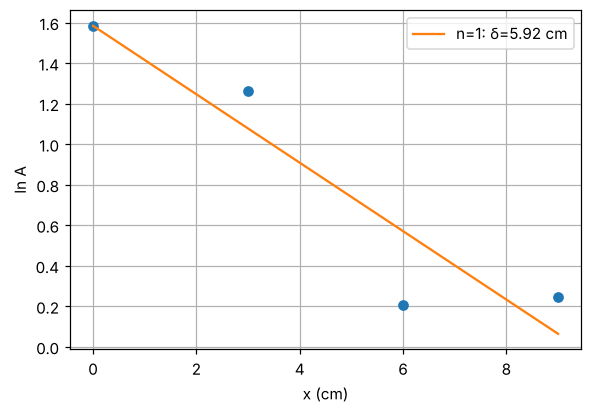

,npts,δ_n (m),± (m),R2
1,4.0,0.059197,0.016533,0.865045


In [11]:
res={}
fig,ax=plt.subplots(figsize=(6,4))
for n in good_n:
    h=H[(H.n==n)&(H.snr>5)]; r=stats.linregress(h.x,np.log(h.A))
    dA=-1/r.slope; sdA=abs(r.stderr/r.slope**2)
    res[n]=dict(slope_lnA=r.slope,err=r.stderr,delta_A=dA,sdelta_A=sdA,R2=r.rvalue**2,npts=len(h))
    ax.plot(h.x*100,np.log(h.A),"o"); ax.plot(h.x*100,r.intercept+r.slope*h.x,"-",label=f"n={n}: δ={dA*100:.2f} cm")
ax.set_xlabel("x (cm)"); ax.set_ylabel("ln A"); ax.legend(); plt.show()
pd.DataFrame(res).T[["npts","delta_A","sdelta_A","R2"]].rename(columns={"delta_A":"δ_n (m)","sdelta_A":"± (m)"})

## Q18 — Velocity of the "wave"
Phase lag of harmonic *n* grows linearly with x: φ_n = x/δ_n + const. The phase velocity is v_n = ω_n/k_n = ω_n δ_n.

In [12]:
for n in good_n:
    h=H[(H.n==n)&(H.snr>5)]; lag=np.unwrap(-h.arg.values)
    # choose branch so lag increases with x
    r=stats.linregress(h.x,lag); wn=2*np.pi*n*f0; dP=1/r.slope; sdP=abs(r.stderr/r.slope**2)
    res[n].update(slope_phase=r.slope,delta_P=dP,sdelta_P=sdP,v=wn*dP,sv=wn*sdP,R2_phase=r.rvalue**2)
pd.DataFrame(res).T[["delta_P","sdelta_P","v","sv","R2_phase"]].rename(columns={"delta_P":"1/k_n (m)","v":"v (m/s)","sv":"± v"})

,1/k_n (m),sdelta_P,v (m/s),± v,R2_phase
1,0.064945,0.007616,0.004081,0.000479,0.973233


## Q19 & Q20 — Thermal diffusivity
From the heat-equation solution, δ = √(2D/ω), so **D = ω δ² / 2**. Q19 uses the phase (velocity) route, Q20 the amplitude (damping) route.

In [13]:
out=[]
for n in good_n:
    wn=2*np.pi*n*f0; r=res[n]
    DP=wn*r["delta_P"]**2/2; sDP=DP*2*r["sdelta_P"]/r["delta_P"]
    DA=wn*r["delta_A"]**2/2; sDA=DA*2*r["sdelta_A"]/r["delta_A"]
    r.update(D_phase=DP,sD_phase=sDP,D_amp=DA,sD_amp=sDA)
    out.append(dict(n=n,f_mHz=n*f0*1e3,D_phase=DP,sD_phase=sDP,D_amp=DA,sD_amp=sDA,
                    dev_phase_pct=100*(DP-D_REF)/D_REF,dev_amp_pct=100*(DA-D_REF)/D_REF))
Dtab=pd.DataFrame(out); pd.options.display.float_format="{:.3g}".format; print("D_ref (Cu) =",D_REF,"m^2/s"); Dtab

D_ref (Cu) = 0.000102 m^2/s


,n,f_mHz,D_phase,sD_phase,D_amp,sD_amp,dev_phase_pct,dev_amp_pct
0,1,10,0.000133,3.11e-05,0.00011,6.15e-05,29.9,7.93


## Q21 — Compare the two routes
Ratio D_phase/D_amp and the percentage difference from the published value. *(Write your comment: which route is more consistent, and why — heat loss through the insulation adds extra damping without changing the phase much, and the sensor spacing is uncertain to ±0.2 cm, which enters as the square.)*

In [14]:
for _,r in Dtab.iterrows():
    print(f"n={int(r.n)}: D_phase/D_amp = {r.D_phase/r.D_amp:.2f};  D_phase vs ref {r.dev_phase_pct:+.0f}%,  D_amp vs ref {r.dev_amp_pct:+.0f}%")
d1=Dtab.iloc[0]; print(f"\nFundamental: D_phase = ({d1.D_phase:.2e} ± {d1.sD_phase:.1e}) m²/s ; D_amp = ({d1.D_amp:.2e} ± {d1.sD_amp:.1e}) m²/s ; ref = {D_REF:.2e}")

n=1: D_phase/D_amp = 1.20;  D_phase vs ref +30%,  D_amp vs ref +8%

Fundamental: D_phase = (1.33e-04 ± 3.1e-05) m²/s ; D_amp = (1.10e-04 ± 6.1e-05) m²/s ; ref = 1.02e-04


## Q23 — Do higher harmonics damp out faster?
Quantitative: amplitude ratio A_n(x_far)/A_n(0) for each harmonic, and δ_n ∝ 1/√n.

In [15]:
rows=[]
for n in good_n:
    h=H[(H.n==n)&(H.snr>5)]; rows.append(dict(n=n,x_far_cm=h.x.max()*100,A0=h.A.iloc[0],A_ratio=h.A.iloc[-1]/h.A.iloc[0],delta_A_cm=res[n]["delta_A"]*100,
        delta_pred_cm=res[1]["delta_A"]*100/np.sqrt(n)))
print(pd.DataFrame(rows).round(3).to_string(index=False))
if len(good_n)>1:
    plt.figure(figsize=(5,3.5)); plt.plot(good_n,[res[n]["delta_A"]*100 for n in good_n],"o",label="measured"); nn=np.linspace(1,max(good_n),50)
    plt.plot(nn,res[1]["delta_A"]*100/np.sqrt(nn),"-",label="δ1/√n"); plt.xlabel("harmonic n"); plt.ylabel("δ_n (cm)"); plt.legend(); plt.show()

 n  x_far_cm   A0  A_ratio  delta_A_cm  delta_pred_cm
 1         9 4.87    0.263        5.92           5.92


## Q24 — Skin depth
δ_n = √(2D/ω_n): the distance over which the amplitude falls to 1/e. Computed with the *measured* D (mean of the two routes at the fundamental) and with the published D.

In [16]:
D_meas=np.mean([res[1]["D_phase"],res[1]["D_amp"]]); w1=2*np.pi*f0
print(f"Fundamental: skin depth with measured D = {np.sqrt(2*D_meas/w1)*100:.2f} cm ; with D_ref = {np.sqrt(2*D_REF/w1)*100:.2f} cm ; measured damping length = {res[1]['delta_A']*100:.2f} cm")

Fundamental: skin depth with measured D = 6.21 cm ; with D_ref = 5.70 cm ; measured damping length = 5.92 cm


## Q25 — Heat flux of the oscillation: does it carry energy?
For the fundamental, T_osc = A e^{−x/δ} cos(ωt − x/δ + θ). Then J = −κ ∂T/∂x. Averaged over one period the oscillating part of J is **zero** (sin/cos average to zero), so there is no net energy transport by the oscillation itself. Only the **mean gradient** (DC part) moves heat from hot to cold end.

peak |J| of oscillation = 48666 W/m²,  time-average over one period = 1.72e+01 W/m²  (≈ 0)


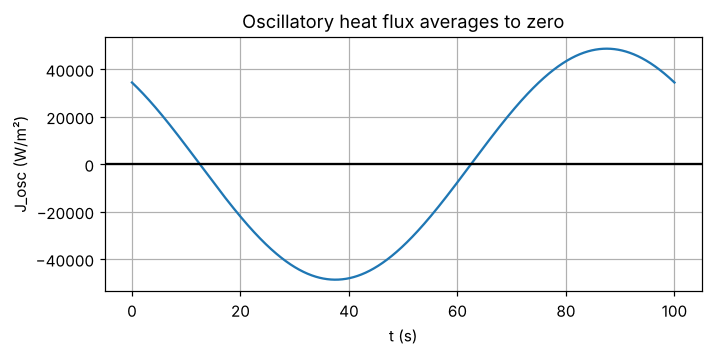

In [17]:
A1=res[1]; d=A1["delta_A"]; Aamp=H[(H.n==1)&(H.ch==ORDER[0])].A.iloc[0]; kap=D_meas*RHO*CP
tp=np.linspace(0,P,2000); xm=0.0
dTdx=-(Aamp/d)*np.exp(-xm/d)*(np.cos(w1*tp-xm/d)-np.sin(w1*tp-xm/d))   # d/dx of A e^{-x/δ}cos(ωt-x/δ)
J=-kap*dTdx
print(f"peak |J| of oscillation = {abs(J).max():.0f} W/m²,  time-average over one period = {J.mean():.2e} W/m²  (≈ 0)")
plt.figure(figsize=(7,3)); plt.plot(tp,J); plt.axhline(0,c="k"); plt.xlabel("t (s)"); plt.ylabel("J_osc (W/m²)"); plt.title("Oscillatory heat flux averages to zero"); plt.show()

## Q26 — The paradox: the heated end *does* get hot
The oscillation transports no energy, but the heater also raises the **mean** temperature (the c₀(x) = P₁x + P₀ term, Eq. 5). The mean temperature has a linear gradient, and **that DC gradient is what carries heat** from the heated end toward the cold end. The "waves" are only the oscillating part riding on top of it.

## Q27 — Thermal conductivity from J = −κ ∇T
(a) From the mean flux and mean-temperature gradient: κ = J̄ / |dT̄/dx|, where J̄ = (average electrical power)/(rod cross-section). The average power is rated power × (V/V_rated)² × duty cycle; this **assumes no heat loss**, so it *underestimates* κ.
(b) From the diffusivity: κ = D ρ c_p.

In [18]:
Pavg=P_RATED*(Vhi/V_RATED)**2*duty; Area=np.pi*(ROD_DIAM/2)**2; Jbar=Pavg/Area
mean_T=np.array([Y[ch].mean() for ch in ORDER]); g=stats.linregress(x,mean_T)
kappa_a=Jbar/abs(g.slope); skappa=kappa_a*abs(g.stderr/g.slope)
print(f"mean T at x: {np.round(mean_T,1)}  -> gradient = {g.slope:.0f} ± {g.stderr:.0f} K/m")
print(f"(a) P_avg = {Pavg:.1f} W, J = {Jbar:.0f} W/m²  ->  κ ≥ {kappa_a:.0f} ± {skappa:.0f} W/m/K  (heat losses ignored)")
for nm,Dv in (("D_phase",res[1]["D_phase"]),("D_amp",res[1]["D_amp"]),("D_ref",D_REF)): print(f"(b) κ = D ρ c  with {nm}: {Dv*RHO*CP:.0f} W/m/K")
print("Literature κ(Cu) ≈ 385–401 W/m/K")

mean T at x: [122.4 119.6 114.7 109.2]  -> gradient = -149 ± 15 K/m
(a) P_avg = 19.1 W, J = 26964 W/m²  ->  κ ≥ 182 ± 18 W/m/K  (heat losses ignored)
(b) κ = D ρ c  with D_phase: 457 W/m/K
(b) κ = D ρ c  with D_amp: 380 W/m/K
(b) κ = D ρ c  with D_ref: 352 W/m/K
Literature κ(Cu) ≈ 385–401 W/m/K


## Save results for the comparison notebook (notebook 4)

In [19]:
summary=dict(label=LABEL,f0_Hz=f0,P_s=P,t_ss_s=float(t_ss),ncyc=int(ncyc),DX=DX,order=ORDER,usable_harmonics=good_n,
  harmonics={int(n):{k:float(v) for k,v in res[n].items()} for n in good_n},
  amplitudes=H.assign(x=H.x).to_dict(orient="list"),mean_T=mean_T.tolist(),grad_K_per_m=float(g.slope),kappa_flux=float(kappa_a),
  kappa_D_phase=float(res[1]["D_phase"]*RHO*CP),kappa_D_amp=float(res[1]["D_amp"]*RHO*CP))
json.dump(summary,open(f"results_{LABEL}.json","w"),indent=1); print("saved results_"+LABEL+".json")

saved results_10mHz.json
